In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 작일 복습 : 상관계수 히트맵

In [2]:
PATH='C:\\ex\\data\\20_cmapss_fd001_sample.csv'
df=pd.read_csv(PATH)

In [4]:
df.corr().values

array([[ 1.00000000e+00,  4.87837396e-02, -1.22879050e-02,
         6.15956549e-02,             nan,             nan,
         8.14080702e-03, -3.24586253e-02,  2.57991522e-02,
                    nan,             nan,  5.52373771e-03,
         1.89987113e-02,  4.74746170e-03,             nan,
         6.64032637e-03, -1.03223367e-03,  3.92764782e-03,
        -1.99863364e-02,  4.27304960e-03,             nan,
        -1.84238565e-03,             nan,             nan,
        -4.78723068e-03, -1.42354109e-02],
       [ 4.87837396e-02,  1.00000000e+00, -4.77289125e-02,
         1.48016063e-02,             nan,             nan,
         8.16644354e-01,  7.15203974e-01,  7.38617068e-01,
                    nan,             nan, -9.01438732e-01,
         7.80208238e-01,  5.77260102e-01,             nan,
         8.42763580e-01, -9.02986761e-01,  6.95280957e-01,
         3.14405612e-01,  8.54386871e-01,             nan,
         7.38349539e-01,             nan,             nan,
        -8.81

In [5]:
# 두 컬럼에 대한 상관계수를 2x2로 출력
import numpy as np

np.corrcoef(df['s_4'], df['s_7'])

array([[ 1.        , -0.76695969],
       [-0.76695969,  1.        ]])

In [6]:
df['s_4'].corr(df['s_7'])

np.float64(-0.7669596882740884)

In [ ]:
# idxmax() 검산법 : iloc[idxmax() 결과값]이 .abs().max()와 같다면 검산 성공

In [ ]:
# 20_03. 실습 6

In [ ]:
# 평균

In [11]:
e2 = df[df['unit_nr'] == 2].sort_values('time_cycles').reset_index(drop=True)
e2['s_11'].rolling(5).mean()
ma=e2['s_11'].rolling(5).mean()

In [12]:
ma.dropna()

4      47.300
5      47.296
6      47.236
7      47.228
8      47.256
        ...  
282    48.230
283    48.142
284    48.146
285    48.124
286    48.152
Name: s_11, Length: 283, dtype: float64

In [13]:
ma.dropna().iloc[-1]

np.float64(48.152)

In [14]:
ma.dropna().iloc[0]

np.float64(47.3)

In [15]:
tr = '상승' if ma.dropna().iloc[-1] > ma.dropna().iloc[0] else '하강'

tr

'상승'

In [ ]:
# 표준편차

In [ ]:
s=e2['s_11'].rolling(5).std()

h=len(e2) // 2  # 143

In [17]:
vol='증가' if s.iloc[h:].mean() > s.iloc[:h].mean() else '감소'

In [ ]:
# 종합

In [18]:
for col in ['s_11', 's_12', 's_3']:
    ma = e2[col].rolling(5).mean()
    tr = '상승' if ma.dropna().iloc[-1] > ma.dropna().iloc[0] else '하강'
    s = e2[col].rolling(5).std(); h = len(e2) // 2
    vol = '증가' if s.iloc[h:].mean() > s.iloc[:h].mean() else '감소'
    print(col, '추세', tr, '변동성', vol)

s_11 추세 상승 변동성 증가
s_12 추세 하강 변동성 감소
s_3 추세 상승 변동성 증가


In [ ]:
# 금일 진도

In [21]:
CM='C:\\ex\\data\\21_cmapss_fd001_sample.csv'
df=pd.read_csv(CM)

In [22]:
e1=df[df['unit_nr'] == 1]

e1

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_2,s_3,s_4,s_7,s_11
0,1,1,0.0010,0.0000,100.0,640.69,1585.21,1399.30,554.17,46.931
1,1,2,-0.0003,-0.0002,100.0,641.13,1585.55,1401.18,554.36,46.857
2,1,3,0.0013,0.0000,100.0,641.25,1584.72,1400.84,554.00,47.220
3,1,4,0.0030,0.0001,100.0,641.97,1585.94,1401.26,554.13,47.152
4,1,5,-0.0005,-0.0002,100.0,641.58,1585.72,1401.36,553.87,46.956
...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0001,-0.0002,100.0,647.63,1606.39,1418.65,549.65,50.814
188,1,189,-0.0017,-0.0002,100.0,647.05,1608.47,1417.50,550.54,50.915
189,1,190,-0.0030,-0.0001,100.0,646.84,1605.65,1417.31,549.79,50.997
190,1,191,-0.0009,-0.0004,100.0,647.34,1606.83,1418.11,549.72,51.151


In [23]:
ma=e1['s_3'].rolling(20).mean()
sd=e1['s_3'].rolling(20).std()

In [ ]:
# 21_01. 실습 1

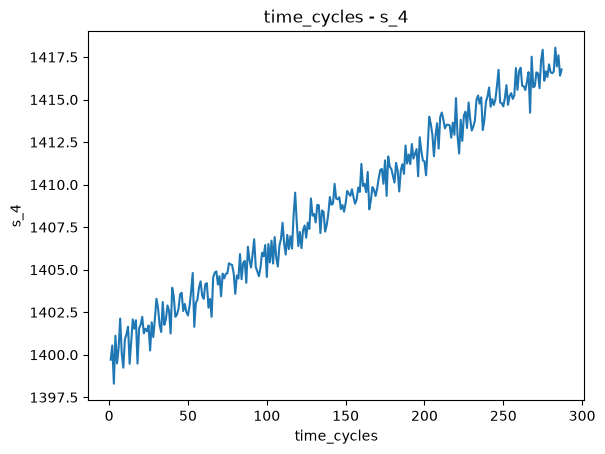

In [29]:
e2=df[df['unit_nr']==2].reset_index(drop=True)

import matplotlib.pyplot as plt

plt.Figure(figsize=(10,8))
plt.plot(e2['time_cycles'], e2['s_4'])
plt.title('time_cycles - s_4')
plt.xlabel('time_cycles')
plt.ylabel('s_4')

plt.show()

In [ ]:
# 21_01. 실습 2

In [ ]:
# window=10으로 이동평균 구하기 -> 변수에 할당
ma10=e2['s_4'].rolling(10).mean()

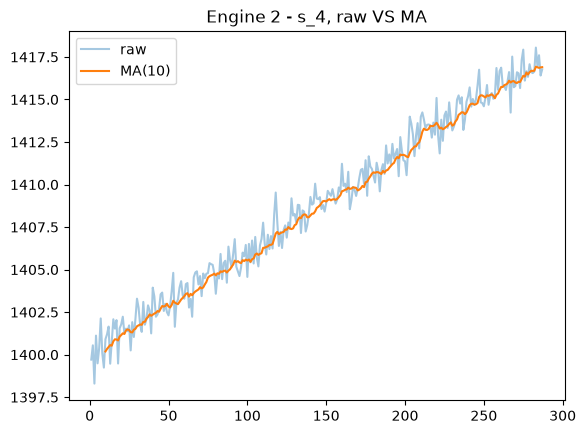

In [34]:
# 원본과 이동평균을 한 그래프에 겹쳐 그리기
import matplotlib.pyplot as plt

# 범례 붙이고 이동평균이 추세를 드러내도록 작성
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.4, label='raw')
plt.plot(e2['time_cycles'], ma10, label='MA(10)')
plt.title('Engine 2 - s_4, raw VS MA')
plt.legend()

plt.show()

In [ ]:
# 21_01. 실습 3

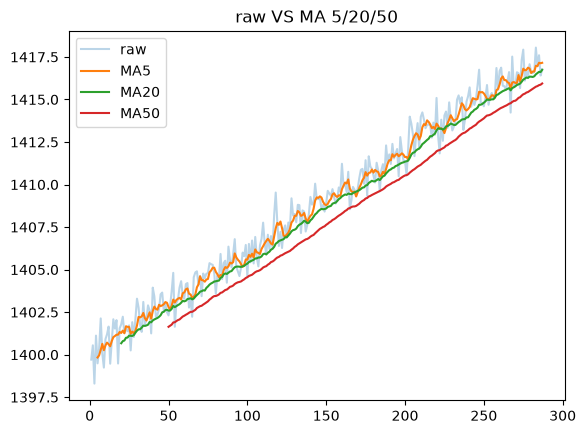

In [36]:
# 원본 데이터 희미하게 출력
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.3, label='raw')

# window = 5, 20, 50일 때, 도출할 이동평균을 for 반복문으로 코드 간소화
for i in [5,20,50]:
    plt.plot(e2['time_cycles'], e2['s_4'].rolling(i).mean(), label=f'MA{i}')

plt.title('raw VS MA 5/20/50')
plt.legend()
plt.show()



In [ ]:
# 21_01. 실습 4

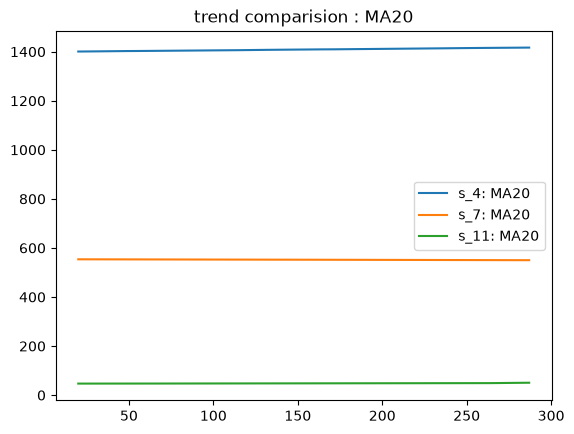

In [41]:
for col in ['s_4', 's_7', 's_11'] :
    plt.plot(e2['time_cycles'], e2[col].rolling(20).mean(), label=f'{col}: MA20')
plt.title('trend comparision : MA20')
plt.legend()
plt.show()

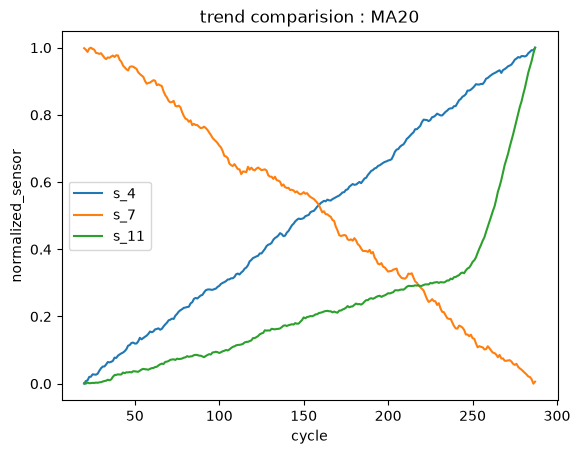

In [44]:
# 정규화(min-max)로 추세를 확실히 드러내기
for col in ['s_4', 's_7', 's_11']:
    ma = e2[col].rolling(20).mean()
    plt.plot(e2['time_cycles'], (ma - ma.min()) / (ma.max() - ma.min()), label=col)

plt.title('trend comparision : MA20')
plt.xlabel('cycle')
plt.ylabel('normalized_sensor')

plt.legend()
plt.show()

In [ ]:
# 21_01. 실습 5

In [46]:
std20=e2['s_3'].rolling(window=20).std()

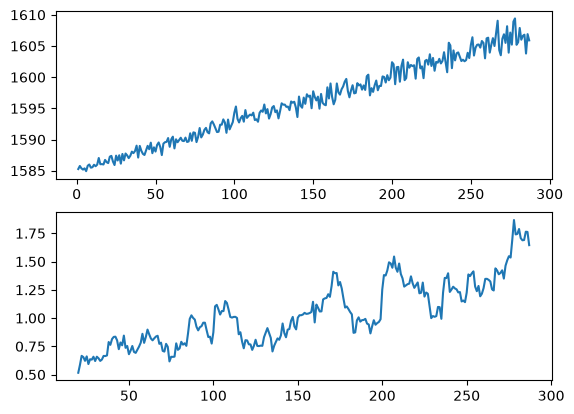

In [48]:
plt.subplot(2,1,1)
plt.plot(e2['time_cycles'], e2['s_3'])
plt.subplot(2,1,2)
plt.plot(e2['time_cycles'], std20)

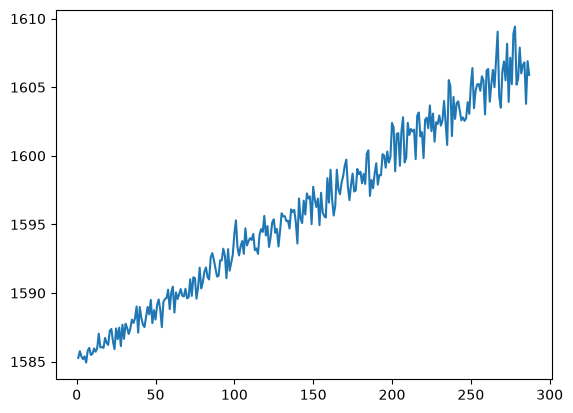

In [49]:
result=plt.plot(e2['time_cycles'], e2['s_3'])

In [51]:
type(result)   # type = list
len(result)   # len(result) = 1

1

In [52]:
type(result[0])   # type = Line2D

matplotlib.lines.Line2D

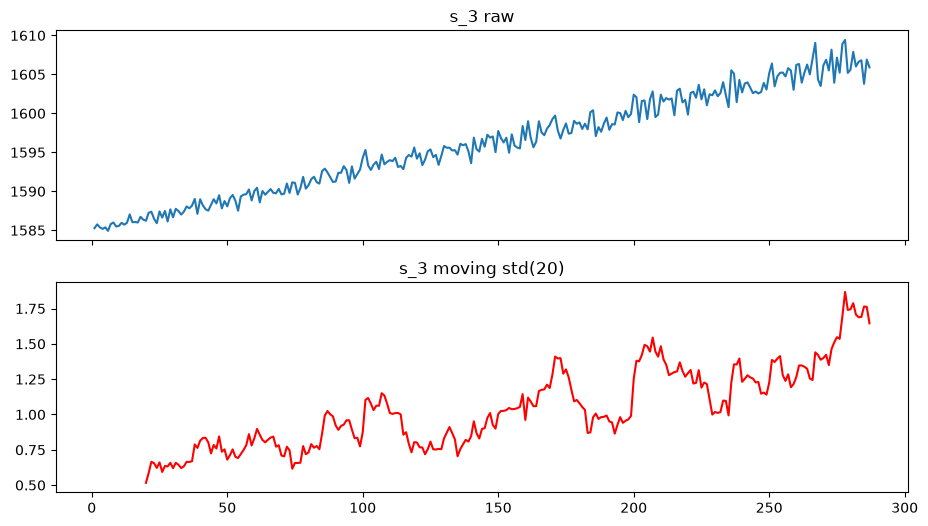

In [56]:
# x축을 공유하면서 subploting 하기
std20=e2['s_3'].rolling(window=20).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11,6), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_3']); ax1.set_title('s_3 raw')
ax2.plot(e2['time_cycles'], std20, color='red'); ax2.set_title('s_3 moving std(20)')

plt.tight_layout
plt.show()

In [ ]:
# 21_01. 실습 6

In [ ]:
# window=20 and s_3의 이동평균
ma = e2['s_3'].rolling(20).mean()

# window=20 and s_3의 이동표준편차
sd = e2['s_3'].rolling(20).std()

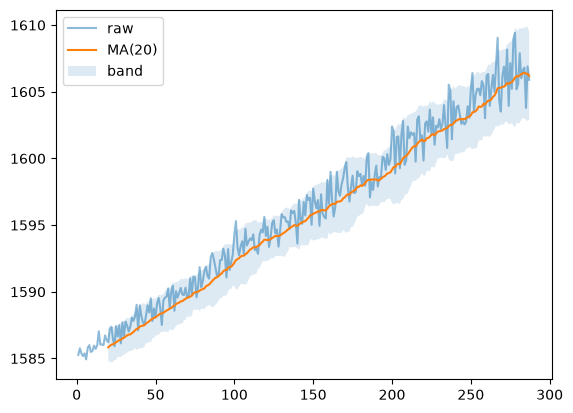

In [60]:
# 원본 데이터
plt.plot(e2['time_cycles'], e2['s_3'], alpha=0.5, label='raw')

# window=20의 이동평균 도시
plt.plot(e2['time_cycles'], ma, label='MA(20)')

# 변동성 밴드 : .fill_between, IQR과 마찬가지로 경계값 이상의 값은 이상치 처리
# 밴드 폭이 넓어질수록 산포도가 증가하여 불안정한 구간으로 판정
plt.fill_between(e2['time_cycles'], ma - 2*sd, ma + 2*sd, alpha=0.15, label='band')

plt.legend()
plt.show()


In [ ]:
# 21_01. 실습 7

C:\Users\user\AppData\Local\Temp\ipykernel_22292\3195093288.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


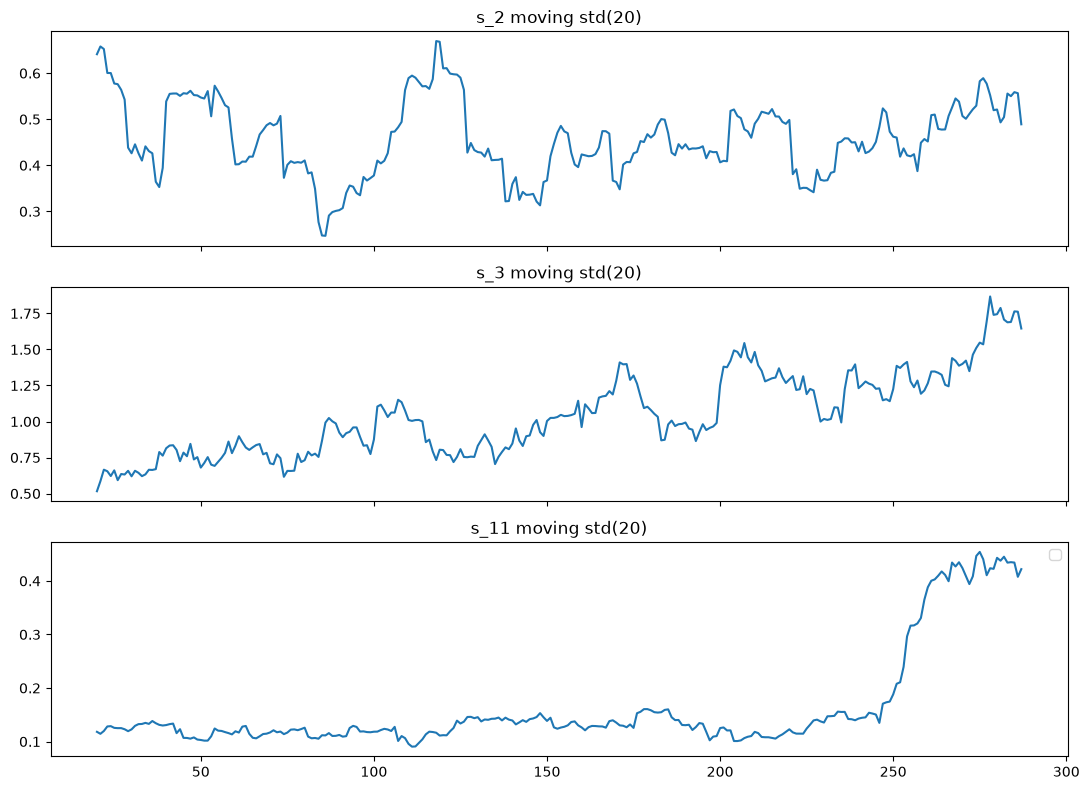

In [63]:
# 분석 센서를 리스트화
ss=['s_2','s_3','s_11']

# x축을 공유 and 3행 1열의 도화지를 작성
# 3행 1열의 도화지는 fig에 할당
# axes의 자료형은 array -> 각 행의 그래프가 array화되어 axes에 할당
# axes[0], axes[1], axes[2]로 각각 1행 1열, 2행 1열, 3행 1열의 데이터만 추출 가능
fig, axes = plt.subplots(3,1, figsize=(11,8), sharex=True)

# zip으로 ax와 col을 언패킹
for ax, col in zip(axes, ss):
    ax.plot(e2['time_cycles'], e2[col].rolling(20).std())
    ax.set_title(col+" moving std(20)")

plt.tight_layout()
plt.legend()

plt.show()

In [ ]:
# 각 데이터 분석
# s_2
# 이동표준편차가 선명한 추세를 보이기 보다는 무작위하게 변동 -> 노이즈 간섭이 심함, 분석이 무의미

# s_3
# 이동표준편차가 꾸준히 증가하고 있음 -> 고장 징후(EX. 열화)의 점진적 누적을 의심, 표준편차가 급변하는 구간에 보고된 이상 징후가 성능 저하의 주요 원인으로 간주될 것

# s_11
# 250 사이클 이전까지, 뚜렷한 변동이 없으나 250 이후로 급격한 변동 발생 -> IF가 큰 고장 징후 발생 가능성 농후 -> 고장 임박

In [65]:
s=pd.Series([100,103,102,108,107])
s.diff()

0    NaN
1    3.0
2   -1.0
3    6.0
4   -1.0
dtype: float64

In [66]:
s.diff(2)

0    NaN
1    NaN
2    2.0
3    5.0
4    5.0
dtype: float64

In [68]:
s.pct_change()

0         NaN
1    0.030000
2   -0.009709
3    0.058824
4   -0.009259
dtype: float64

In [67]:
s.pct_change(2)

0         NaN
1         NaN
2    0.020000
3    0.048544
4    0.049020
dtype: float64

In [ ]:
# 21_02. 실습 1

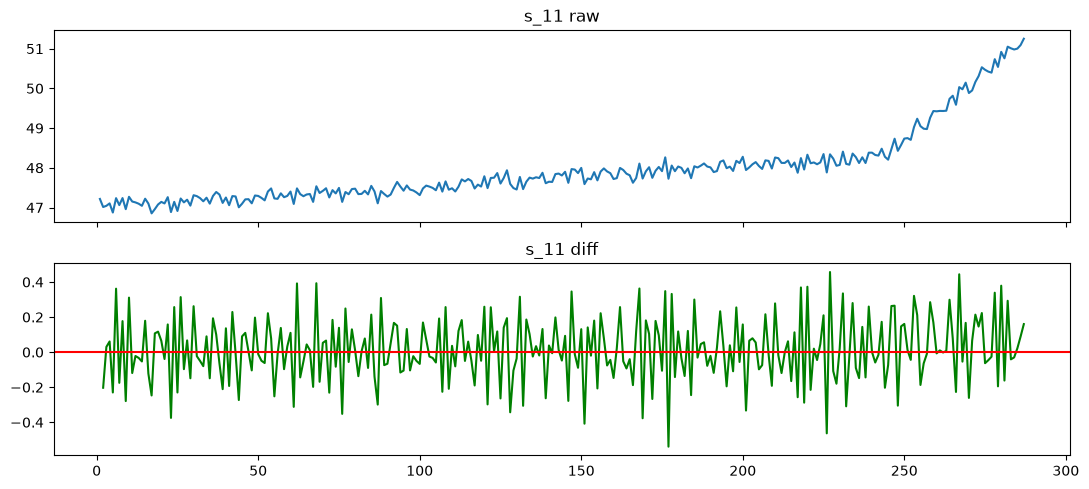

In [71]:
import matplotlib.pyplot as plt

# 2번 엔진의 센서 11의 직전 대비 변화량 구해서 변수에 할당
e2_s11_diff=e2['s_11'].diff()

# 위칸에 원본, 아래칸에 변화량과 0 기준선 그리기
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(11,5), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_11'])
ax1.set_title('s_11 raw')  # 원본 데이터 위칸에 배치

ax2.plot(e2['time_cycles'], e2_s11_diff, color='green') # 차분 데이터 녹색으로 그리기
ax2.axhline(0, color='red') # 0 기준선 붉은색으로 그리기
ax2.set_title('s_11 diff')

plt.tight_layout()
plt.show()

In [72]:
CH='C:\\ex\\data\\21_cmapss_fd001_sample.csv'
TS='C:\\ex\\data\\21_engine1_timestamp_sample.csv'

df=pd.read_csv(CH)

In [73]:
e2=df[df['unit_nr']==2].reset_index(drop=True)

In [ ]:
# 21_02. 실습 2

In [75]:
# s_3에 대해 이동평균, 이동표준편차, 차분을 각 변수에 할당
col='s_3'
ma=e2[col].rolling(20).mean()
sd=e2[col].rolling(20).std()
diff=e2[col].diff()

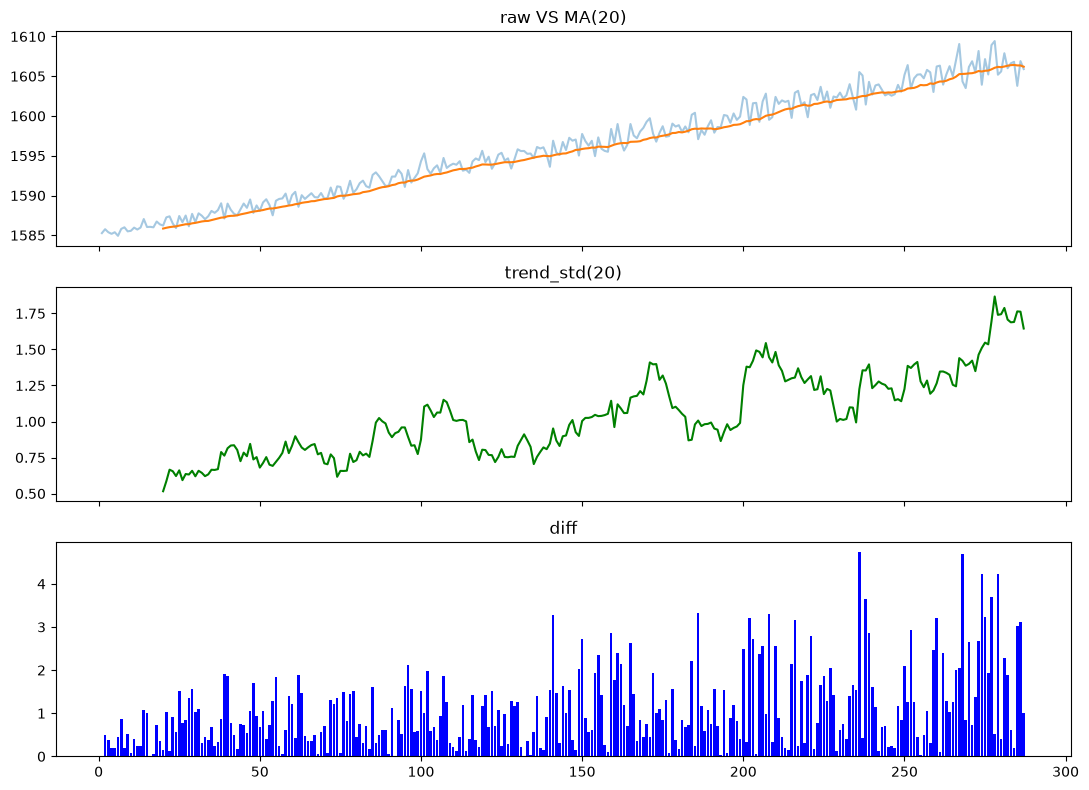

In [85]:
# 세 칸으로 나눠 원본과 추세, 변동성, 변화량을 그리기
fig, axes = plt.subplots(3,1,figsize=(11,8), sharex=True)

# 첫 칸 : 원본과 추세(MA)
axes[0].plot(e2['time_cycles'], e2[col], alpha=0.4)
axes[0].plot(e2['time_cycles'], ma)
axes[0].set_title('raw VS MA(20)')

# 두 번째 칸 : 변동성(STD)
axes[1].plot(e2['time_cycles'], sd, color='green')
axes[1].set_title('trend_std(20)')

# 세 번째 칸 : 변화량(diff)
axes[2].bar(e2['time_cycles'], abs(diff), color='blue')
axes[2].set_title('diff')

plt.tight_layout()
plt.show()

In [ ]:
# 21_02. 실습 3

In [ ]:
# 시각 글자를 시각 값으로 바꿔 인덱스로 올리기

# 데이터 불러오기
CH='C:\\ex\\data\\21_cmapss_fd001_sample.csv'
TS='C:\\ex\\data\\21_engine1_timestamp_sample.csv'

ts=pd.read_csv(TS)

# 시간의 자료형을 str에서 date로 변환
ts['timestamp'] = pd.to_datetime(ts['timestamp'])

# 결측치 확인
ts.isna().sum().sum()  # 0

# date의 자료형으로 변환된 timestamp 컬럼을 인덱스로 세팅
ts=ts.set_index('timestamp')

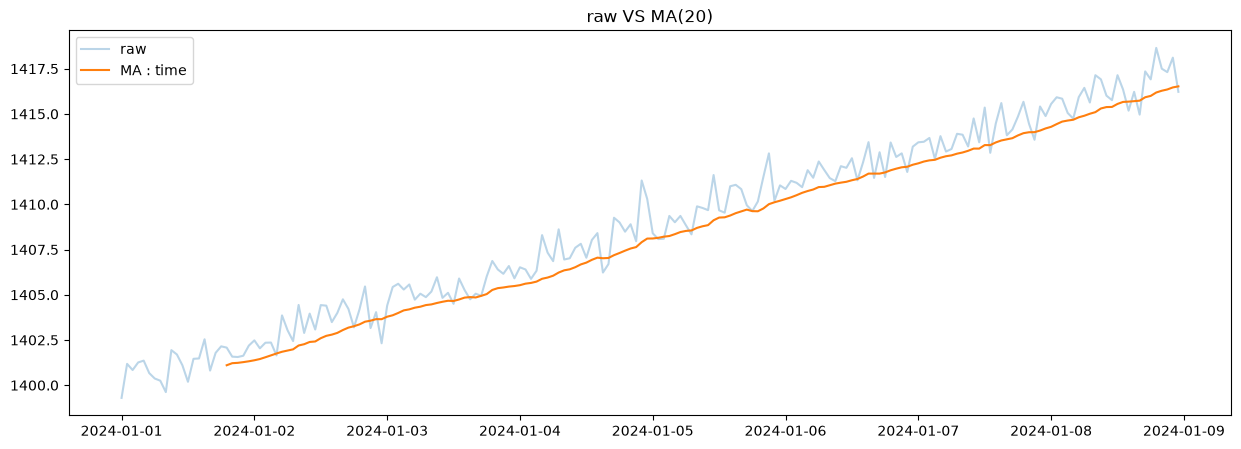

In [93]:
# 원본을 옅게, 시간 이동평균을 진하게 겹쳐 그리기

plt.figure(figsize=(15,5))
# 원본을 옅게
plt.plot(ts.index, ts['s_4'], alpha=0.3, label='raw')

# 시간 이동평균을 짙게
plt.plot(ts.index, ts['s_4'].rolling(20).mean(), alpha=1, label='MA : time')

plt.title('raw VS MA(20)')
plt.legend()
plt.show()

In [ ]:
# timestamp의 자료형을 str에서 date로 바꾸기 전에 결측치가 존재하는지부터 확인할 것
# df['timestamp'].isna().sum()

In [ ]:
# 21_02 실습 4

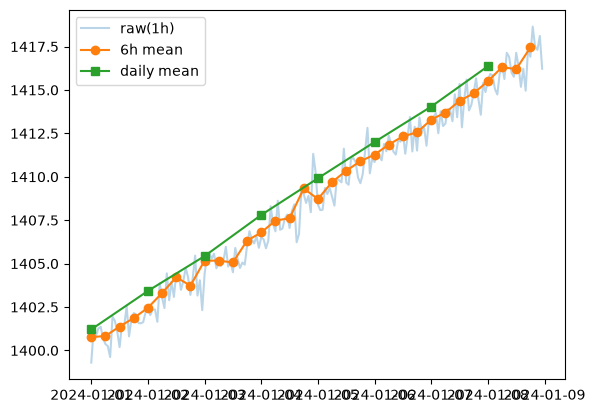

In [96]:
h6 = ts['s_4'].resample('6h').mean()
day = ts['s_4'].resample('D').mean()

plt.plot(ts.index, ts['s_4'], alpha=0.3, label='raw(1h)')

plt.plot(h6.index, h6, marker='o', label='6h mean')

plt.plot(day.index, day, marker='s', label='daily mean')

plt.legend()
plt.show()

In [97]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
seasonal_decompose